# Step 04. 사전 정의 샘플 기반 경로 계획 (Pre-defined Sample-based Planner)

> **참고**: PythonRobotics (https://github.com/AtsushiSakai/PythonRobotics) — original author Atsushi Sakai (@Atsushi_twi) / License MIT 코드 참고
>
> **교육 주관**: Hanyang University, Automotive Intelligence Laboratory (AILAB)

미리 정해진 패턴(predefined pattern)으로 여러 경로 후보를 만들고, 그중 비용이 가장 낮은 안전한 후보 하나를 고르는 경로 계획입니다. 이 노트북에서는 종방향 속도 프로파일을 하나로 고정하고, 횡방향으로 여러 목표 위치를 샘플링해 후보를 만든 뒤, 비용과 충돌 검사를 거쳐 최적 경로를 선택합니다.

> **실습 안내**: 각 `##### TODO #####` 펜스 안을 채운 뒤, 위에서부터 차례로 실행하세요.
> - TODO 1 (섹션 3): 5차 다항식의 끝점 경계조건 `de, de_d, de_dd`
> - TODO 2 (섹션 3): 계수 행렬 $A$ (3×3) 채우기
> - TODO 3 (섹션 5): 비용 함수 (jerk + 목표 offset)
> - TODO 4 (섹션 7): 비용이 가장 낮은 유효 후보 선택

## 학습 목표

1. Frenet frame: 경로를 기준으로 한 $(s, d)$ 좌표 이해
2. 종방향 $s(t)$ 프로파일 고정 (등속 CV)
3. 횡방향 목표 offset $d_i$ 를 샘플링해 5차 다항식으로 후보 경로 생성
4. Frenet $\rightarrow$ Cartesian 변환으로 후보를 도로 위에 표현 (utils 변환기 사용)
5. 비용 함수와 충돌 검사로 후보를 평가하고 최적 경로 선택

## 0. Setup & 시나리오

기준 경로(reference path)는 waypoint 를 cubic spline 으로 보간해 만듭니다. 도로 위에 장애물 몇 개를 두고, 차량의 초기 상태(시작 위치·횡방향 offset)와 샘플링·비용 파라미터를 한곳에 모읍니다.

In [ ]:
%matplotlib inline
import sys, os
sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('../utils/02_trajectory_planning'))

import numpy as np
import matplotlib.pyplot as plt

from step04_predefined_sample_based_planner import (
    ReferencePath, frenet_path_to_cartesian, show_road,
    plot_frenet_frame_concept, plot_longitudinal_profile,
    plot_lateral_candidates_frenet, plot_candidates_cartesian,
    plot_candidates_cost, plot_validity, plot_best,
)

In [49]:
# ----- 기준 경로 (waypoint -> cubic spline) -----
WP_X = [0.0, 20.0, 40.0, 60.0, 80.0]
WP_Y = [0.0,  3.0,  0.0, -3.0,  0.0]
ref = ReferencePath(WP_X, WP_Y, ds=0.1)

# ----- 장애물 (x, y) 와 안전 반경 -----
OBSTACLES = [[22.0, 1.5], [40.0, 1.0], [58.0, -2.5]]
ROBOT_RADIUS = 1.5

# ----- 횡방향 샘플링 -----
MAX_ROAD_WIDTH = 6.0   # 좌우 최대 offset [m]
D_ROAD_W       = 1.0   # offset 샘플 간격 [m]
DS             = 0.5   # 경로 길이 s 샘플 간격 [m]

# ----- 차량 초기 상태 -----
S0     = 0.0           # 시작 위치의 경로 거리 s (arc length, 시작점이면 0)
C_D    = 0.0           # 시작 횡방향 위치 d
C_D_D  = 0.0           # 시작 횡방향 속도 d'
C_D_DD = 0.0           # 시작 횡방향 가속도 d''
V      = 30.0 / 3.6    # 종방향 등속 [m/s]
T_HORIZON = 6.0        # 계획 구간 시간 [s]

# ----- 비용 가중치 -----
K_J = 0.1              # 횡방향 jerk 비용
K_D = 1.0              # 목표 offset 비용

print(f'path length = {ref.length:.1f} m,  horizon s in [{S0:.0f}, {S0 + V * T_HORIZON:.0f}] m')

path length = 80.9 m,  horizon s in [0, 50] m


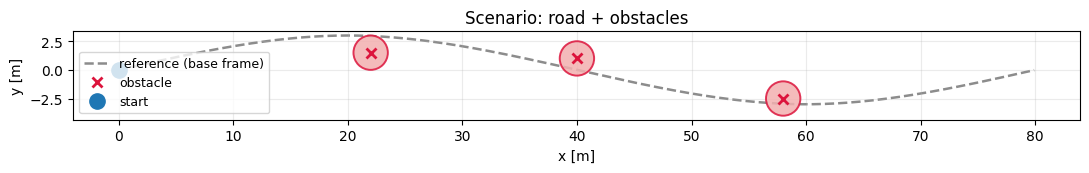

In [50]:
# 시작 위치(기준점에서 횡방향으로 C_D 만큼 떨어진 곳)
start_x = ref.x[0] - np.sin(ref.yaw[0]) * C_D
start_y = ref.y[0] + np.cos(ref.yaw[0]) * C_D

show_road(ref, OBSTACLES, ROBOT_RADIUS, start=(start_x, start_y))

## 1. Frenet frame — 경로를 기준으로 한 $(s, d)$ 좌표

도로처럼 구조화된 환경에서는 좌표를 $x, y$ 로 보는 대신 **기준 경로(base frame)를 따라** 보는 것이 편합니다. 경로 위의 한 점을 두 값으로 나타냅니다.

- $s$ : 경로를 따라 잰 거리(arc length) — "얼마나 멀리 갔는가"
- $d$ : 경로에서 수직으로 떨어진 횡방향 거리 — "중심선에서 얼마나 옆에 있는가" (왼쪽 +)

이렇게 보면 "차선을 따라가며 옆으로 얼마나 비킬까"를 그대로 $d$ 로 표현할 수 있어, 횡방향 회피 경로를 만들기 쉬워집니다.

아래 그림은 **같은 한 점**을 (a) 굽은 Cartesian 경로와 (b) 곧게 편 Frenet $(s, d)$ 평면에서 비교합니다. 경로를 곧게 펴면 $(s, d)$ 가 그대로 가로·세로 좌표가 되어, 횡방향 회피를 직관적으로 다룰 수 있습니다.

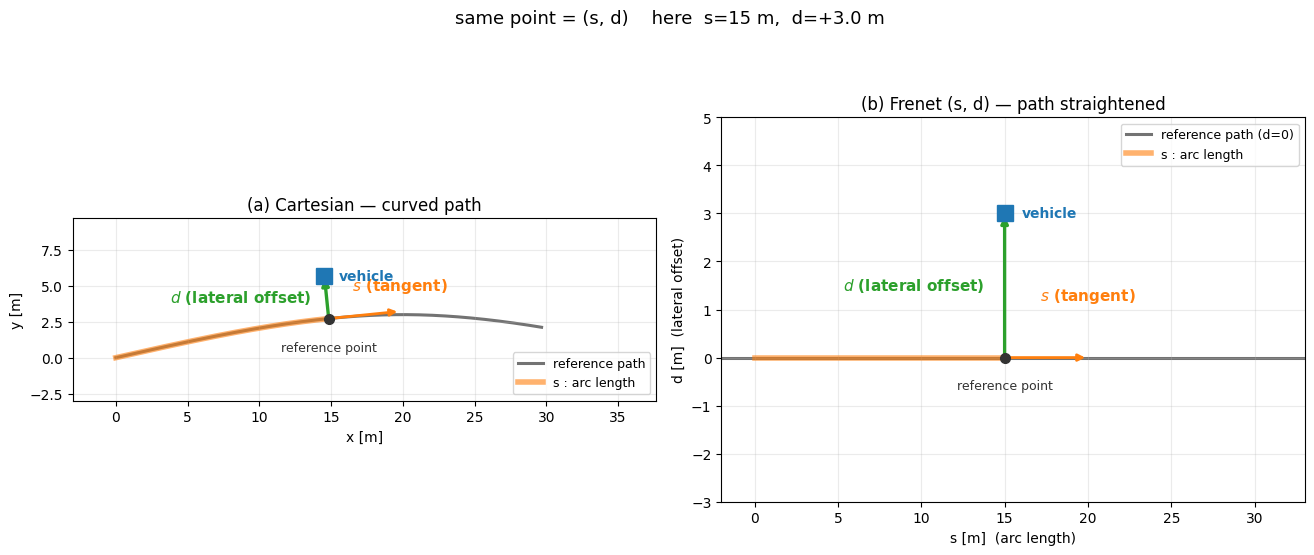

In [51]:
plot_frenet_frame_concept(ref, s_query=15.0, d_query=3.0)

## 2. 종방향 $s(t)$ 프로파일 고정

이번 실습에서는 "얼마나 빨리 나아갈지"를 정하는 종방향 프로파일 $s(t)$ 를 **하나로 고정**합니다. 가장 단순한 등속(CV) 프로파일을 씁니다.

$$ s(t) = s_0 + v\,t $$

(가속 프로파일(CA)도 같은 틀로 확장할 수 있지만, 여기서는 CV 하나만 사용합니다.)

종방향을 고정했으므로 후보는 **횡방향**에서만 갈라집니다. 계획 구간의 끝 경로 거리는 $s_1 = s_0 + v\,T$ 이고, 이 구간을 $\Delta s$ 간격으로 샘플링합니다.

> 일반적인 Frenet planner 는 $s(t)$ 와 $d(s)$ 를 모두 샘플링할 수 있지만, 여기서는 핵심인 횡방향 후보 생성에 집중하기 위해 종방향을 고정합니다.

s0 = 0.0 m,  s1 = 50.0 m,  s 샘플 수 = 101


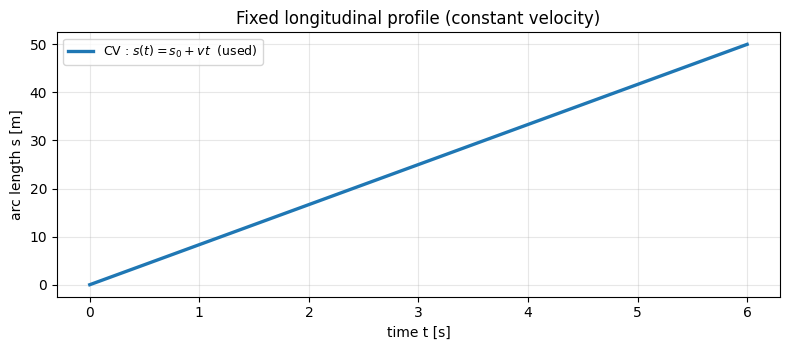

In [52]:
s1 = S0 + V * T_HORIZON
s_arr = np.arange(S0, s1 + DS/2, DS)   # 끝점 s1 까지 포함 (마지막 점이 목표 offset 에 정확히 안착)
print(f's0 = {S0:.1f} m,  s1 = {s1:.1f} m,  s 샘플 수 = {len(s_arr)}')

plot_longitudinal_profile(S0, V, T_HORIZON)

## 3. 횡방향 후보 생성 — 5차 다항식

고정된 종방향에 대해, 여러 **목표 lateral offset $d_i$** 를 샘플링합니다. 각 $d_i$ 마다 현재 횡방향 상태에서 그 offset 까지 **부드럽게** 이어지는 곡선 $d(u)$ 를 하나 만듭니다. ($u = s - s_0$, 구간 길이 $T = s_1 - s_0$)

부드러움을 위해 양 끝점에서 위치·기울기·곡률($d, d', d''$)을 지정합니다. 조건이 6개이므로 5차 다항식을 씁니다.

$$ d(u) = a_0 + a_1 u + a_2 u^2 + a_3 u^3 + a_4 u^4 + a_5 u^5 $$

| 조건 | 시작점 $u=0$ | 끝점 $u=T$ |
|---|---|---|
| 위치 $d$ | $d(0) = c_d$ | $d(T) = d_i$ |
| 1차 미분 $d'$ | $d'(0) = c_d'$ | $d'(T) = 0$ |
| 2차 미분 $d''$ | $d''(0) = c_d''$ | $d''(T) = 0$ |

끝에서 $d' = d'' = 0$ 으로 두면 목표 offset 에 부드럽게 안착합니다.

**계수 구하기.** $d(u)$ 를 미분하면 (거듭제곱 법칙 $\frac{d}{du}u^k = k\,u^{k-1}$):

$$
\begin{aligned}
d'(u)  &= a_1 + 2 a_2 u + 3 a_3 u^2 + 4 a_4 u^3 + 5 a_5 u^4 \\
d''(u) &= 2 a_2 + 6 a_3 u + 12 a_4 u^2 + 20 a_5 u^3
\end{aligned}
$$

**시작점 $u=0$** 을 넣으면 $u$ 가 붙은 항이 모두 사라져 계수가 바로 나옵니다.

$$ a_0 = c_d, \qquad a_1 = c_d', \qquad a_2 = c_d'' / 2 $$

**끝점 $u=T$** 에서는 세 식에 $T$ 를 대입하고 끝조건 $(d_i, 0, 0)$ 을 겁니다. 이미 아는 $a_0, a_1, a_2$ 항을 우변으로 넘기면 좌변에는 미지수 $a_3, a_4, a_5$ 만 남고, **그 계수가 그대로 행렬 $A$** 가 됩니다.

$$
\underbrace{\begin{bmatrix} T^3 & T^4 & T^5 \\ 3T^2 & 4T^3 & 5T^4 \\ 6T & 12T^2 & 20T^3 \end{bmatrix}}_{A}
\begin{bmatrix} a_3 \\ a_4 \\ a_5 \end{bmatrix}
=
\begin{bmatrix} d_i - (a_0 + a_1 T + a_2 T^2) \\ 0 - (a_1 + 2 a_2 T) \\ 0 - 2 a_2 \end{bmatrix}
$$

- **각 행** = 끝점 조건 하나 — 1행 위치 $d(T)$, 2행 기울기 $d'(T)$, 3행 곡률 $d''(T)$.
- **각 열** = 미지수 하나 ($a_3, a_4, a_5$); 한 칸은 "그 식에서 그 미지수에 붙는 계수". 예) 1행은 $d(T)$ 의 $a_3 u^3, a_4 u^4, a_5 u^5$ 에 $u=T$ 를 넣은 $T^3, T^4, T^5$.
- **세로로 내려갈수록 한 번씩 미분** — $a_3$ 열 $T^3 \to 3T^2 \to 6T$, $a_4$ 열 $T^4 \to 4T^3 \to 12T^2$, $a_5$ 열 $T^5 \to 5T^4 \to 20T^3$ (2행은 1행을, 3행은 2행을 미분).

아래 코드에서 두 가지를 직접 채웁니다 — **(1) 끝점 경계조건** 과, 그 조건으로 계수를 푸는 **(2) 계수 행렬 $A$**.

In [ ]:
class Candidate:
    """하나의 횡방향 후보 경로 (Frenet 곡선 + 이후 채울 Cartesian/비용/유효성)."""
    def __init__(self, di, s, d, d_d, d_dd, d_ddd):
        self.di = di                                                # 목표 lateral offset
        self.s, self.d = s, d                                       # Frenet: 경로 거리 s, 횡 offset d(s)
        self.d_d, self.d_dd, self.d_ddd = d_d, d_dd, d_ddd          # d 의 s 에 대한 1/2/3차 미분
        self.x = self.y = self.yaw = self.kappa = self.v = None     # Cartesian (4장에서 채움)
        self.cost = None                                            # 5장에서 채움
        self.valid = True                                           # 6장에서 채움


def quintic_coeffs(d0, d0_d, d0_dd, de, de_d, de_dd, T):
    """양 끝 경계조건 6개로 5차 다항식 d(u)=a0+...+a5 u^5 의 계수를 구한다.

    시작점 u=0 의 세 조건은 a0, a1, a2 를 바로 준다.
    끝점 u=T 의 세 조건은 a3, a4, a5 에 대한 3x3 선형계 A x = b 로 푼다.
    """
    a0 = d0           # d(0)   = a0
    a1 = d0_d         # d'(0)  = a1
    a2 = d0_dd / 2.0  # d''(0) = 2 a2

    ##### TODO #####
    # 끝점 u=T 에서 [d(T), d'(T), d''(T)] 가 [de, de_d, de_dd] 가 되도록,
    # 미지수 [a3, a4, a5] 의 계수 행렬 A (3x3) 를 채우세요.  (markdown 의 선형계 참고)
    #   1행 = 위치 d(T) 식의 a3,a4,a5 계수 / 2행 = d'(T) / 3행 = d''(T)
    #################

    A = np.array([[   T**3,    T**4,    T**5],
                  [ 3*T**2,  4*T**3,  5*T**4],
                  [ 6*T,    12*T**2, 20*T**3]])

    #################

    # 우변 b = 끝 조건 - (이미 정해진 a0,a1,a2 가 만드는 몫)
    b = np.array([de   - (a0 + a1*T + a2*T**2),
                  de_d - (a1 + 2*a2*T),
                  de_dd - 2*a2])
    a3, a4, a5 = np.linalg.solve(A, b)
    return np.array([a0, a1, a2, a3, a4, a5])


def eval_poly(coeffs, u):
    """다항식 값과 1·2·3차 미분을 u(배열)에서 평가."""
    a0, a1, a2, a3, a4, a5 = coeffs
    d     = a0 + a1*u + a2*u**2 + a3*u**3 + a4*u**4 + a5*u**5
    d_d   = a1 + 2*a2*u + 3*a3*u**2 + 4*a4*u**3 + 5*a5*u**4
    d_dd  = 2*a2 + 6*a3*u + 12*a4*u**2 + 20*a5*u**3
    d_ddd = 6*a3 + 24*a4*u + 60*a5*u**2
    return d, d_d, d_dd, d_ddd


def generate_lateral_candidates(s_arr, s0, s1, c_d, c_d_d, c_d_dd):
    u = s_arr - s0
    T = s1 - s0
    candidates = []
    for di in np.arange(-MAX_ROAD_WIDTH, MAX_ROAD_WIDTH + D_ROAD_W, D_ROAD_W):
        # 시작점 u=0 : 차량의 현재 횡방향 상태 그대로
        d0, d0_d, d0_dd = c_d, c_d_d, c_d_dd

        ##### TODO #####
        # 끝점 u=T 의 경계조건 3개를 정하세요.
        #   - 끝 위치 d        : 목표 offset 으로
        #   - 끝 기울기 d', 곡률 d'' : 목표선에 '부드럽게 안착'하려면?  (§1·경계조건표 참고)
        #################

        de, de_d, de_dd = di, 0.0, 0.0

        #################

        coeffs = quintic_coeffs(d0, d0_d, d0_dd, de, de_d, de_dd, T)
        d, d_d, d_dd, d_ddd = eval_poly(coeffs, u)
        candidates.append(Candidate(di, s_arr, d, d_d, d_dd, d_ddd))
    return candidates


candidates = generate_lateral_candidates(s_arr, S0, s1, C_D, C_D_D, C_D_DD)
print(f'생성된 후보 수 = {len(candidates)}')
print(f'목표 offset d_i = {[round(c.di, 1) for c in candidates]}')

생성된 후보 수 = 13
목표 offset d_i = [-6.0, -5.0, -4.0, -3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0]


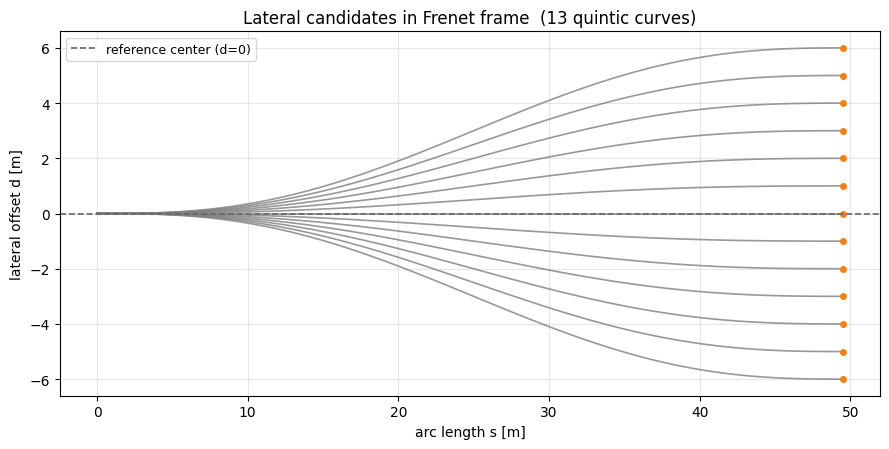

In [54]:
plot_lateral_candidates_frenet(candidates)

## 4. 후보를 도로 위로 — Frenet $\rightarrow$ Cartesian

Frenet 좌표 $(s, d)$ 로 만든 후보를 실제 도로 위 $(x, y)$ 로 옮깁니다. 변환 수식 자체는 이 실습의 핵심이 아니므로 `utils.frenet` 의 변환기를 그대로 사용합니다 (`frenet_path_to_cartesian` 이 내부에서 호출). 변환하면 위치뿐 아니라 방향·곡률·속도도 함께 얻어 다음 단계의 제약 검사에 쓸 수 있습니다.

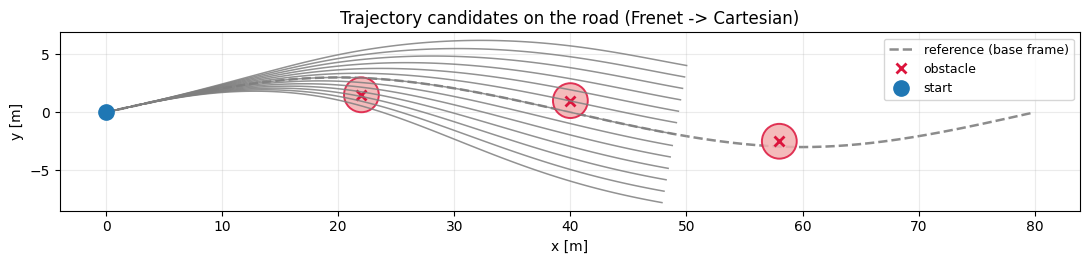

In [55]:
for cand in candidates:
    out = frenet_path_to_cartesian(ref, cand.s, cand.d, cand.d_d, cand.d_dd,
                                   s_d=V, s_dd=0.0)
    cand.x, cand.y = out['x'], out['y']
    cand.yaw, cand.kappa, cand.v = out['yaw'], out['kappa'], out['v']

plot_candidates_cartesian(ref, OBSTACLES, ROBOT_RADIUS, candidates,
                          start=(start_x, start_y))

## 5. 비용 함수 — 어떤 후보가 좋은가

후보마다 비용을 매겨 "좋음"을 수치화합니다. 여기서는 두 가지를 봅니다.

- **부드러움**: 횡방향 jerk(3차 미분) 제곱합이 작을수록 좋음 — 급격한 조향 변화를 피함
- **목표 추종**: 최종 offset $d_i$ 가 중심선(0)에 가까울수록 좋음 — 불필요하게 멀리 비키지 않음

$$ \text{cost} = K_J \sum d'''(s)^2 + K_D \, d_i^2 $$

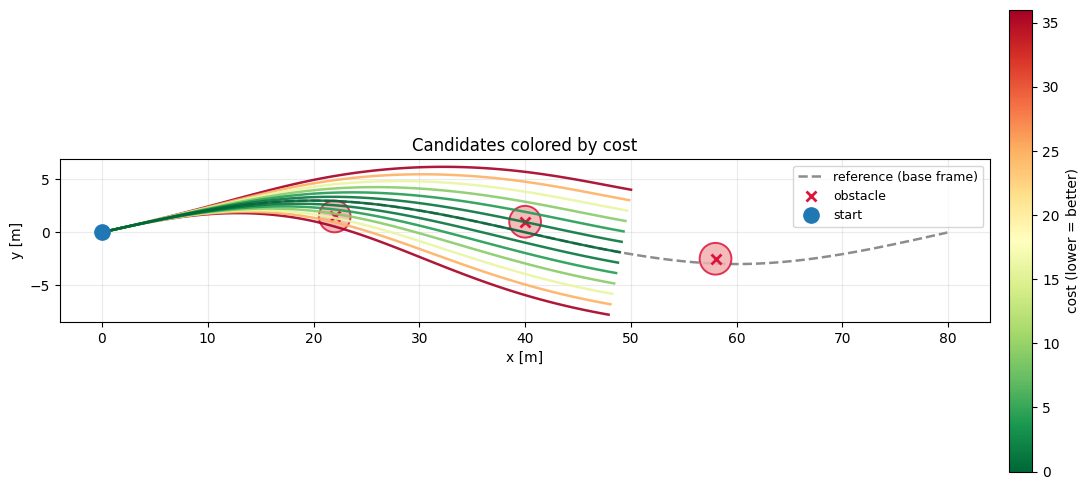

In [56]:
def compute_cost(candidates):
    for cand in candidates:
        ##### TODO #####
        # 비용 = 횡방향 jerk 제곱합 * K_J  +  목표 offset 제곱 * K_D
        #################

        cand.cost = K_J * np.sum(cand.d_ddd ** 2) + K_D * cand.di ** 2

        #################


compute_cost(candidates)
plot_candidates_cost(ref, OBSTACLES, ROBOT_RADIUS, candidates,
                     start=(start_x, start_y))

## 6. 제약·충돌 검사 — 갈 수 있는 후보만 남기기

비용이 낮아도 장애물과 부딪히면 쓸 수 없습니다. 각 후보의 경로 점이 어떤 장애물과도 안전 반경 안으로 들어오지 않는지 검사해, 통과한 후보만 유효(valid)로 표시합니다. (속도·곡률 한계 같은 다른 제약도 같은 자리에서 함께 검사할 수 있습니다.)

유효 후보 = 4 / 13


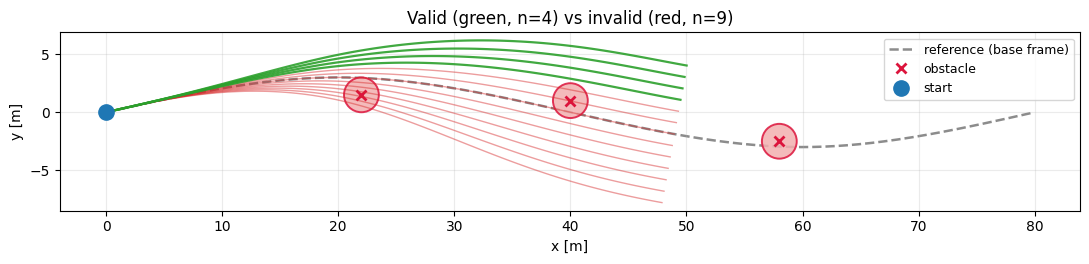

In [57]:
def check_collision(cand, obstacles, robot_radius):
    for ox, oy in obstacles:
        dist2 = (cand.x - ox) ** 2 + (cand.y - oy) ** 2
        if np.any(dist2 <= robot_radius ** 2):
            return False        # 한 점이라도 반경 안 -> 충돌
    return True


for cand in candidates:
    cand.valid = check_collision(cand, OBSTACLES, ROBOT_RADIUS)

n_valid = sum(c.valid for c in candidates)
print(f'유효 후보 = {n_valid} / {len(candidates)}')
plot_validity(ref, OBSTACLES, ROBOT_RADIUS, candidates, start=(start_x, start_y))

## 7. Best candidate 선택

유효한 후보 중에서 비용이 가장 낮은 하나를 최종 경로로 고릅니다. 이것이 sample-based planner 의 결론입니다 — 미리 만든 후보들 중 "안전하면서 가장 비용이 낮은" 것.

best: 목표 offset d_i = +3.0 m,  cost = 9.00


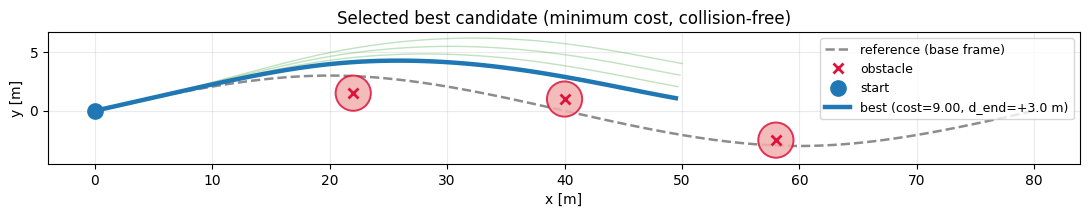

In [58]:
def select_best(candidates):
    best, best_cost = None, float('inf')
    for cand in candidates:
        ##### TODO #####
        # 유효(valid)하면서 cost 가 지금까지의 최솟값보다 작으면 best 갱신
        #################

        if cand.valid and cand.cost < best_cost:
            best_cost, best = cand.cost, cand

        #################
    return best


best = select_best(candidates)
if best is None:
    print('유효한 후보가 없습니다 (모두 충돌).')
else:
    print(f'best: 목표 offset d_i = {best.di:+.1f} m,  cost = {best.cost:.2f}')

plot_best(ref, OBSTACLES, ROBOT_RADIUS, candidates, best, start=(start_x, start_y))

---

## 정리

- 종방향을 고정하고 횡방향 목표 offset $d_i$ 만 샘플링해, 각 후보를 5차 다항식 $d(s)$ 로 부드럽게 생성했습니다.
- Frenet $\rightarrow$ Cartesian 변환(utils 블랙박스)으로 후보를 도로 위에 옮기고, 비용과 충돌 검사로 평가해 최적 경로를 선택했습니다.
- 이 흐름이 "predefined pattern 으로 후보 생성 $\rightarrow$ 최소 비용 후보 선택" 이라는 sample-based planner 의 핵심입니다.